In [1]:
# === LOAD: locate repo and load `sessions` with all_data_df ===
import sys, pickle
from pathlib import Path
import pandas as pd

# Try to discover the repo root from the current notebook location
start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
for p in (start, *start.parents):
    if p.name == "syllable_generation":
        REPO_ROOT = p
        break
else:
    # fallback to your known absolute path
    REPO_ROOT = Path("/home/fsp585/Desktop/FiberphotometryCode/syllable_generation")

# Make package importable (optional, but matches your pattern)
PKG_PARENT = REPO_ROOT.parent
for pth in (str(PKG_PARENT), str(REPO_ROOT)):
    if pth not in sys.path:
        sys.path.insert(0, pth)

# Optional sanity check for the package
try:
    import importlib; importlib.import_module("syllable_generation")
except Exception as e:
    print("Warning: could not import `syllable_generation` (not fatal):", e)

# Default PKL path from your earlier snippet
PKL = REPO_ROOT / "loaders" / "jonathan_ifdn_sessions_w_all_data.pkl"

# Fallback: search for a suitable PKL if the default is missing
if not PKL.exists():
    loaders_dir = REPO_ROOT / "loaders"
    candidates = list(loaders_dir.glob("*sessions*all_data*.pkl")) + list(loaders_dir.glob("*.pkl"))
    if not candidates:
        raise FileNotFoundError(f"Could not find a sessions pickle under {loaders_dir}")
    # pick the most recent
    PKL = max(candidates, key=lambda p: p.stat().st_mtime)
    print(f"Using fallback pickle: {PKL}")

with PKL.open("rb") as f:
    sessions = pickle.load(f)

print(f"Loaded {len(sessions)} sessions from {PKL}")

# Keep only sessions that actually have non-empty all_data_df
sessions = [
    s for s in sessions
    if hasattr(s, "all_data_df") and isinstance(s.all_data_df, pd.DataFrame) and not s.all_data_df.empty
]
print(f"Usable sessions with all_data_df: {len(sessions)}")

# Quick peek
if sessions:
    s0 = sessions[0]
    sid  = getattr(s0, "session_id", "<no id>")
    geno = (getattr(s0, "metadata", {}) or {}).get("genotype", "UNK")
    print(f"Example session: {sid} | genotype={geno}")
    display(s0.all_data_df.head())
else:
    raise RuntimeError("No usable sessions found; check your pickle or preprocessing.")


Using fallback pickle: /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/jonathan_ifdn_sessions_w_sylls_datta.pkl


/tmp/ipykernel_330410/873917099.py:42: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  sessions = pickle.load(f)


Loaded 19 sessions from /home/fsp585/Desktop/FiberphotometryCode/syllable_generation/loaders/jonathan_ifdn_sessions_w_sylls_datta.pkl
Usable sessions with all_data_df: 19
Example session: 2024-12-13T12_20_06_bottom_left | genotype=WT


,name,centroid_x,centroid_y,heading,angular_velocity,velocity_px_s,syllable,frame_index,group,onset,...,signal_0_zscore_datta,signal_1_dff,signal_1_zscore,signal_1_zscore_datta,signal_2_dff,signal_2_zscore,signal_2_zscore_datta,signal_3_dff,signal_3_zscore,signal_3_zscore_datta
0,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.051823,199.522437,-1.122018,0.000000,0.000000,56,69517,WT,True,...,0.184223,-0.456758,-0.635931,-0.340642,-0.342478,-0.795487,-1.069808,-0.565258,-0.636459,-0.929925
1,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,166.903142,199.062367,-1.122018,0.012100,14.504940,56,69518,WT,False,...,0.354767,-0.457280,-0.642150,-0.387259,-0.341230,-0.789986,-1.013056,-0.565216,-0.636034,-0.836198
2,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.223306,199.104034,-1.122018,0.027302,9.685929,56,69519,WT,False,...,0.525311,-0.457802,-0.648369,-0.433876,-0.339982,-0.784485,-0.956304,-0.565174,-0.635609,-0.742470
3,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,167.995061,199.575542,-1.136146,0.046672,27.131755,56,69520,WT,False,...,0.695854,-0.458323,-0.654588,-0.480492,-0.338734,-0.778983,-0.899552,-0.565133,-0.635184,-0.648743
4,Arena1234_CenterTopCamVid_2024-12-13T12_20_06_...,168.522242,201.069801,-1.122018,0.068494,47.535846,56,69521,WT,False,...,0.953528,-0.457493,-0.644689,-0.433324,-0.338548,-0.778165,-0.903196,-0.563833,-0.621913,-0.496993


In [4]:
from collections import defaultdict

# Setup counters
# Key: (Genotype, Region, Hemisphere, Color) -> Set of Animal IDs
group_counts = defaultdict(set)

print(f"{'ID':<8} | {'Geno':<5} | {'Valid':<5} | {'Kept Signals'}")
print("-" * 80)

for s in sessions:
    aid = str(s.metadata.get("animal_id", "UNK"))
    geno = str(s.metadata.get("genotype", "UNK"))
    smeta = s.metadata.get("signal_meta", {})
    
    kept_list = []
    
    for k, info in smeta.items():
        reg = info.get("brain_reg", "UNK")
        hemi = info.get("hemisphere", "?")
        col = info.get("orig_letter", "?")
        
        # --- THE FILTER ---
        # We only count it if it has a real region name
        if reg != "UNK":
            # Add to list for this animal
            kept_list.append(f"{reg}-{hemi}-{col}")
            
            # Add to global stats (using set to count unique animals)
            group_key = (geno, reg, hemi, col)
            group_counts[group_key].add(aid)

    # Print row for this animal
    print(f"{aid:<8} | {geno:<5} | {len(kept_list):<5} | {', '.join(kept_list)}")

print("-" * 80)
print("\n=== FINAL DATASET COUNT (Unique Animals per Group) ===")
print(f"{'GENO':<6} {'REGION':<8} {'HEMI':<6} {'COLOR':<6} | {'N'}")
print("-" * 45)

# Sort by Region, then Hemi, then Geno
sorted_keys = sorted(group_counts.keys(), key=lambda x: (x[1], x[2], x[0]))

for (g, r, h, c) in sorted_keys:
    if g == "UNK": continue
    n = len(group_counts[(g, r, h, c)])
    print(f"{g:<6} {r:<8} {h:<6} {c:<6} | {n}")

ID       | Geno  | Valid | Kept Signals
--------------------------------------------------------------------------------
740      | WT    | 4     | DMS-L-G, DMS-L-R, VS-R-G, VS-R-R
1666     | KI    | 4     | DMS-L-G, DMS-L-R, VS-R-G, VS-R-R
1658     | KI    | 4     | DLS-L-G, DLS-L-R, VS-R-G, VS-R-R
1678     | UNK   | 4     | DLS-L-G, DLS-L-R, DMS-R-G, DMS-R-R
1664     | KI    | 4     | DMS-L-G, DMS-L-R, DLS-R-G, DLS-R-R
1680     | WT    | 4     | DLS-L-G, DLS-L-R, VS-R-G, VS-R-R
728      | WT    | 4     | VS-L-G, VS-L-R, DLS-R-G, DLS-R-R
1694     | KI    | 4     | VS-L-G, VS-L-R, DMS-R-G, DMS-R-R
1773     | WT    | 4     | DMS-L-G, DMS-L-R, DLS-R-G, DLS-R-R
1775     | WT    | 4     | VS-L-G, VS-L-R, DMS-R-G, DMS-R-R
1771     | KI    | 2     | VS-R-G, VS-R-R
1751     | UNK   | 4     | DLS-L-G, DLS-L-R, VS-R-G, VS-R-R
1755     | UNK   | 0     | 
1749     | KI    | 2     | DLS-L-G, DLS-L-R
1767     | WT    | 4     | VS-L-G, VS-L-R, DLS-R-G, DLS-R-R
1765     | WT    | 2     | VS-R-G, VS-R

Scanning 19 sessions...
Generating 3x2 Grid...


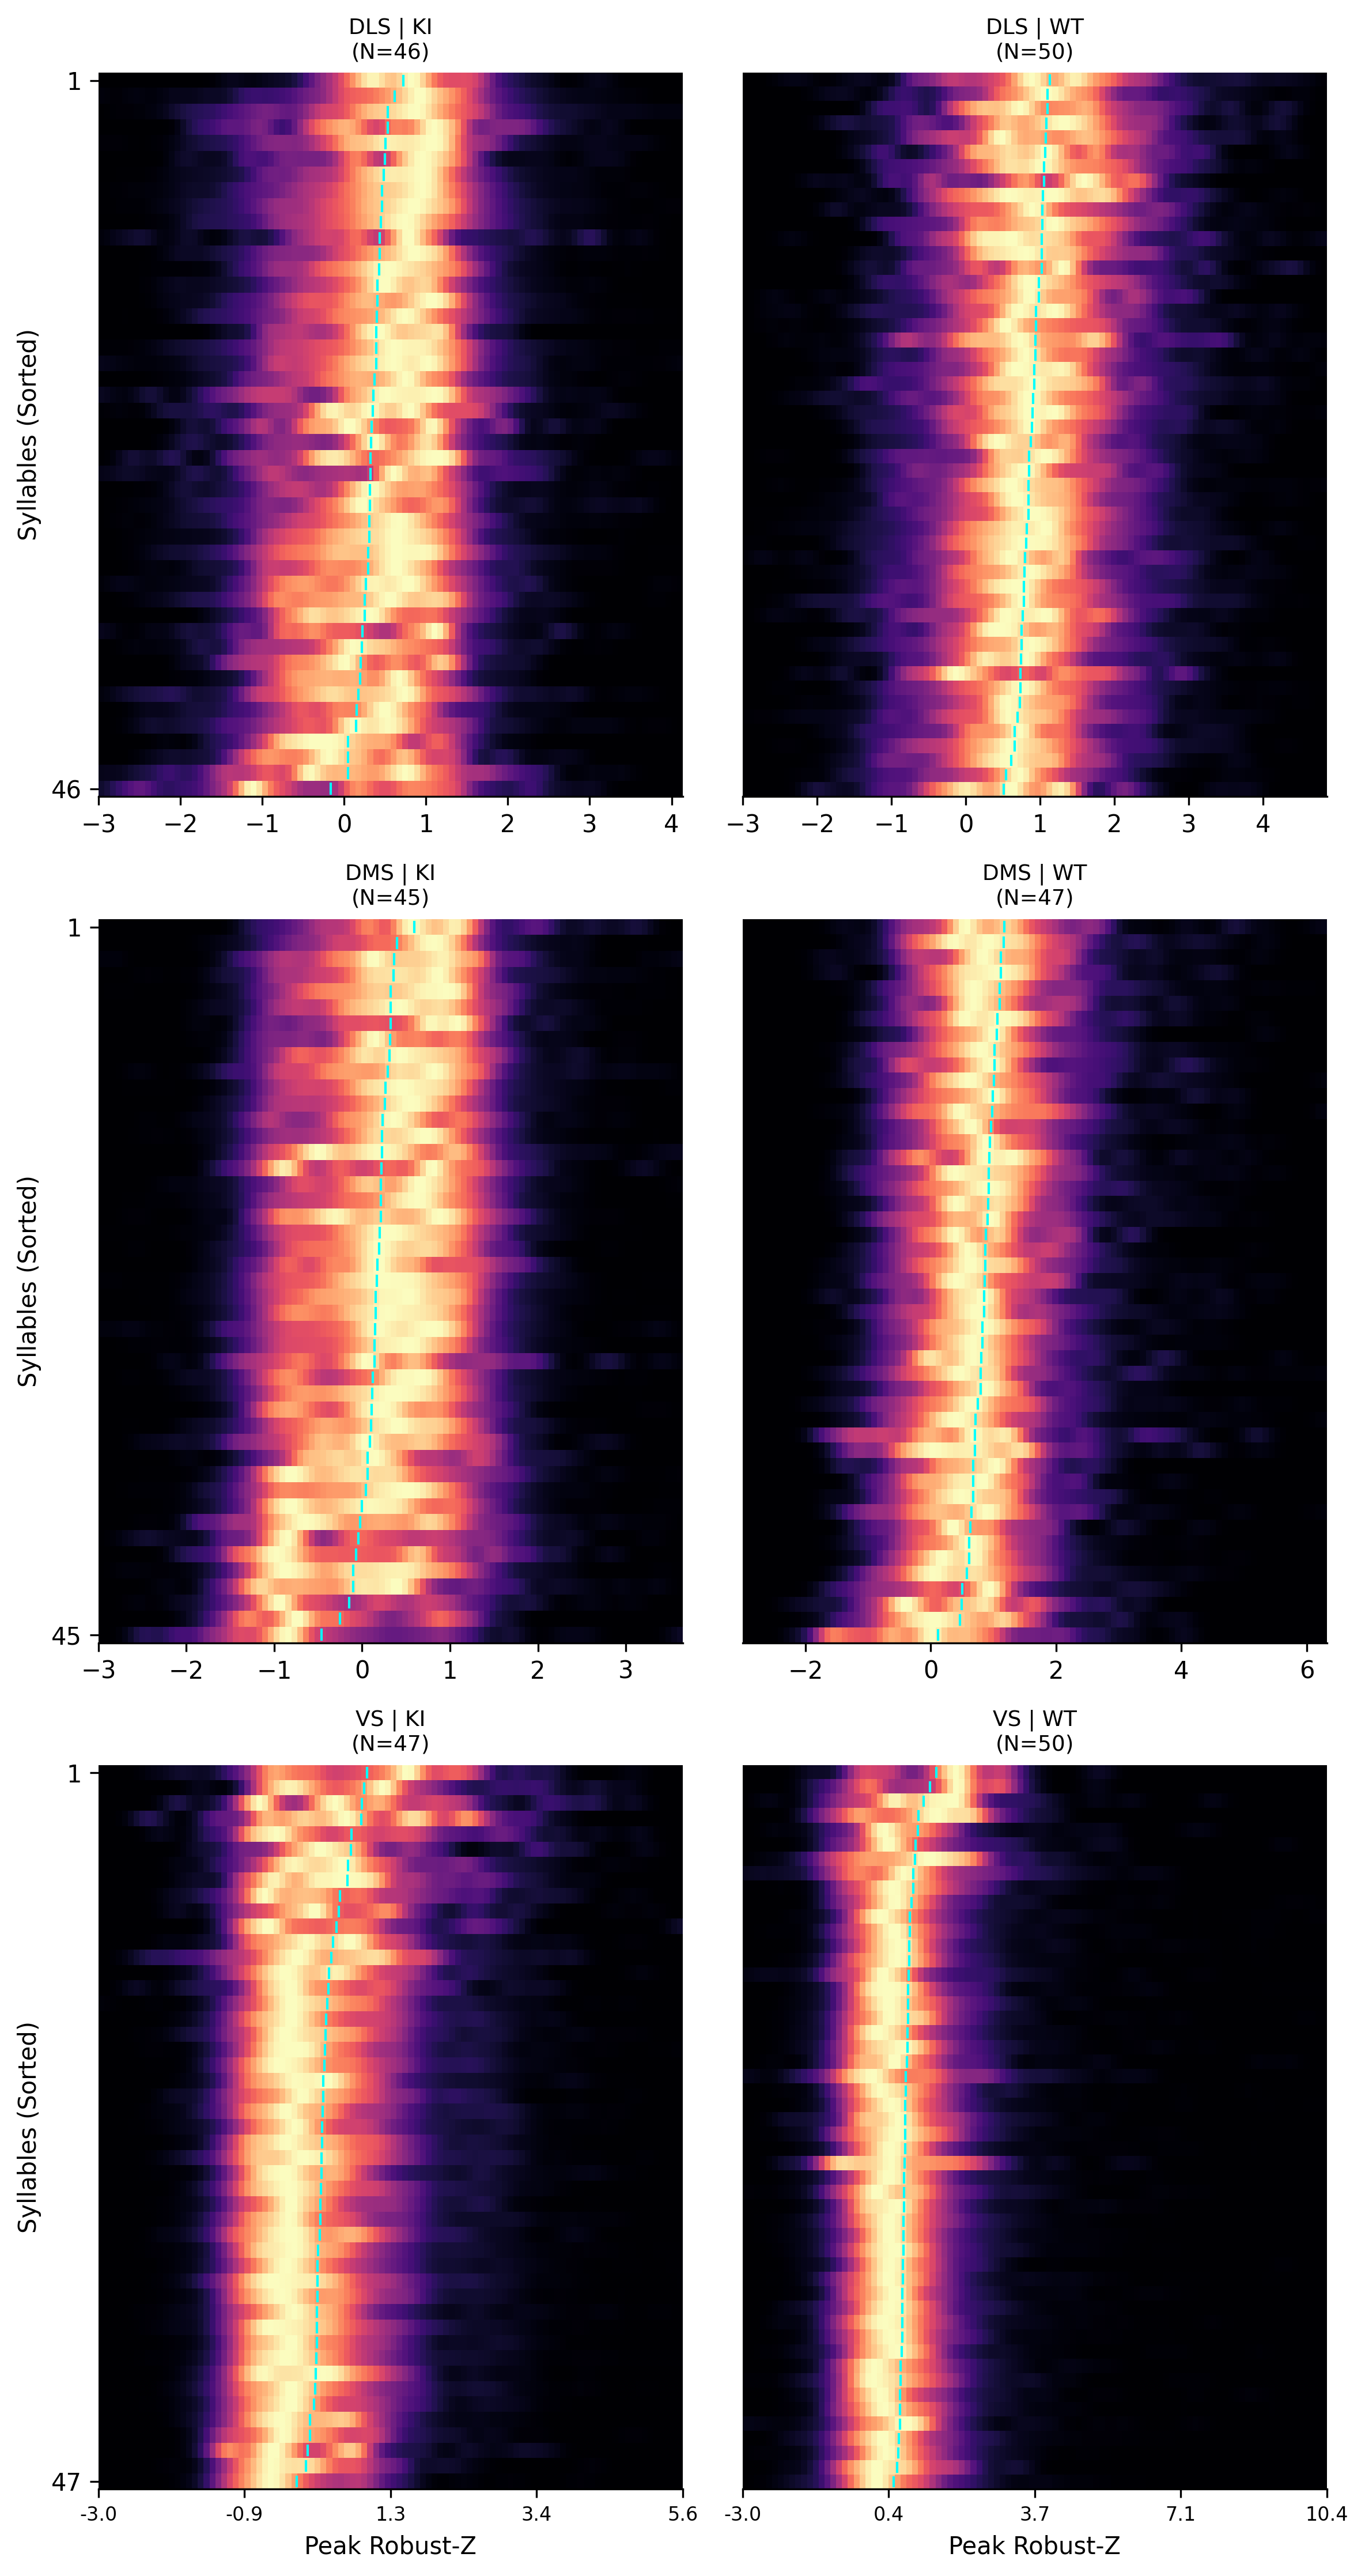

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from collections import defaultdict

# ==========================================
# 1. CONFIGURATION (Hybrid Replication)
# ==========================================
# --- BOUNDARIES (The "Original Notebook" Logic) ---
# The original code used: range=(-0.025, quantile(0.99))
# For Z-Scores, -0.025 is too high (cuts off negatives). 
# We use -2.0 as a standard "Baseline" lower bound.
X_LOWER_BOUND = -3.0       
# Upper bound determined by this percentile of the data (filters extreme outliers)
X_UPPER_QUANTILE = 0.999    

# --- VISUALIZATION ---
BIN_COUNT = 100            # Resolution
CMAP = "magma"
SMOOTHING_SIGMA = 2      # Row-wise smoothing strength
ROW_WISE_NORM = True       # Maximize brightness per row

# --- FILTERS ---
WINDOW_SECONDS = 0.3       # 0-300ms window
MIN_TRIALS = 100           # Drop rare syllables
REMOVE_IMMEDIATE = True    # Drop decay artifacts (t < 25ms)
KEEP_TOP_N_SYLLABLES = 50  # Keep N cleanest syllables

# --- NORMALIZATION ---
USE_ROBUST_Z = True        # Median/MAD (Z-to-Shuffle mimic)

# --- DATA ---
IGNORE_GENOTYPES = {"UNK", None, "nan"}
IGNORE_REGIONS = {"UNK", None, "nan"}
TARGET_ORIG_LETTER = "G" 

# ==========================================
# 2. DATA AGGREGATION
# ==========================================
data_buckets = defaultdict(lambda: defaultdict(list))

print(f"Scanning {len(sessions)} sessions...")

import re 

def clean_region_name(raw_name):
    """Converts 'L-DLS' -> 'DLS', 'R-VS' -> 'VS'"""
    if not raw_name: return "UNK"
    # Remove L- or R- prefix (case insensitive) followed by any separator
    s = re.sub(r"^[LRlr][\s\-_]+", "", str(raw_name))
    return s.strip().upper()

for session in sessions:
    geno = session.metadata.get("genotype", "UNK")
    if geno in IGNORE_GENOTYPES: continue
    df = session.all_data_df
    if df.empty: continue
    
    # Rate & Onsets
    if "SystemTimestamp" in df.columns and len(df) > 1:
        dt = np.median(np.diff(df["SystemTimestamp"]))
        fs = 1 / dt
    else: fs = 30.0 
    window_frames = int(WINDOW_SECONDS * fs)
    
    if "onset" in df.columns:
        onsets = df["onset"].fillna(0).astype(bool).to_numpy()
    else:
        onsets = (df["syllable"] != df["syllable"].shift(1)).fillna(False).to_numpy()
    onset_indices = np.flatnonzero(onsets)
    syllable_array = df["syllable"].to_numpy()
    
    # Signal Extraction
    sig_meta = session.metadata.get("signal_meta", {})
    for sig_key, info in sig_meta.items():
        
        # --- METADATA EXTRACTION & CLEANING (THE DELTA) ---
        raw_region = info.get("brain_reg", "UNK")
        region = clean_region_name(raw_region) 
        
        # Robust Hemisphere Check: Use explicit key OR infer from raw name
        hemi = str(info.get("hemisphere", "")).upper()
        if not hemi or hemi == "UNK":
            if str(raw_region).upper().startswith("L"): hemi = "L"
            elif str(raw_region).upper().startswith("R"): hemi = "R"
        
        color = str(info.get("orig_letter", "")).upper()
        if not color and "fiber_num" in info:
            color = "G" if int(info["fiber_num"]) % 2 == 0 else "R"
            
        # --- FILTERS ---
        if region in IGNORE_REGIONS or region == "UNK": 
            continue
            
        # Prefer Raw DFF
        col_name = None
        if f"{sig_key}_dff" in df.columns: col_name = f"{sig_key}_dff"
        elif f"{sig_key}_zscore_datta" in df.columns: col_name = f"{sig_key}_zscore_datta"
        elif f"{sig_key}_zscore" in df.columns: col_name = f"{sig_key}_zscore"
        if col_name is None: continue

        signal_data = df[col_name].to_numpy()
        
        # Robust Baseline
        if USE_ROBUST_Z and "dff" in col_name:
            sess_med = np.nanmedian(signal_data)
            sess_mad = np.nanmedian(np.abs(signal_data - sess_med)) * 1.4826
            if sess_mad == 0: sess_mad = 1.0
        
        current_peaks = []
        for idx in onset_indices:
            if idx + window_frames >= len(signal_data): continue
            
            segment = signal_data[idx : idx + window_frames]
            peak_val = np.max(segment)
            
            peak_frame = np.argmax(segment)
            peak_time = peak_frame / fs 
            if REMOVE_IMMEDIATE and peak_time < 0.025: continue

            if USE_ROBUST_Z and "dff" in col_name:
                final_val = (peak_val - sess_med) / sess_mad
            else:
                final_val = peak_val

            current_peaks.append({
                "syllable": syllable_array[idx],
                "peak": final_val,
                "peak_time": peak_time
            })
            
        if current_peaks:
            data_buckets[geno][region].append(pd.DataFrame(current_peaks))

# ==========================================
# 3. PLOTTING (Fixed Boundary Logic)
# ==========================================
unique_genos = sorted(data_buckets.keys())
unique_regions = sorted({r for g in data_buckets for r in data_buckets[g]})

print(f"Generating {len(unique_regions)}x{len(unique_genos)} Grid...")

fig, axes = plt.subplots(
    nrows=len(unique_regions), ncols=len(unique_genos), 
    figsize=(4 * len(unique_genos), 5 * len(unique_regions)),
    dpi=300, sharex=False, sharey=False
)

if len(unique_regions) == 1 and len(unique_genos) == 1: axes = np.array([[axes]])
elif len(unique_regions) == 1: axes = axes[np.newaxis, :]
elif len(unique_genos) == 1: axes = axes[:, np.newaxis]

for r_idx, region in enumerate(unique_regions):
    for c_idx, geno in enumerate(unique_genos):
        ax = axes[r_idx, c_idx]
        chunks = data_buckets[geno].get(region, [])
        
        if not chunks:
            ax.text(0.5, 0.5, "No Data", ha='center', va='center'); continue
            
        feat_df = pd.concat(chunks, ignore_index=True)
        
        # --- FILTER 1: Counts ---
        counts = feat_df["syllable"].value_counts()
        valid = counts[counts >= MIN_TRIALS].index
        feat_df = feat_df[feat_df["syllable"].isin(valid)]
        
        # --- FILTER 2: Center-Cut ---
        if KEEP_TOP_N_SYLLABLES and len(feat_df) > 0:
            global_med = feat_df["peak_time"].median()
            syll_meds = feat_df.groupby("syllable")["peak_time"].median()
            best_sylls = (syll_meds - global_med).abs().nsmallest(KEEP_TOP_N_SYLLABLES).index
            feat_df = feat_df[feat_df["syllable"].isin(best_sylls)]

        # --- SORTING ---
        syll_means = feat_df.groupby("syllable")["peak"].mean()
        sorting = syll_means.sort_values(ascending=False).index.tolist()
        
        if not sorting:
            ax.text(0.5, 0.5, "No valid syllables", ha='center', va='center'); continue

        # --- CALCULATE BOUNDARIES (Reference Logic) ---
        # Lower Bound: Fixed (e.g. -2.0)
        # Upper Bound: 99th Percentile of the data (e.g. ~5.0)
        view_min = X_LOWER_BOUND
        view_max = feat_df["peak"].quantile(X_UPPER_QUANTILE)
        
        # Safety check
        if view_max <= view_min: view_max = view_min + 1.0
        
        # Create edges spanning strictly this range
        edges = np.linspace(view_min, view_max, BIN_COUNT + 1)
        
        # --- DENSITY ---
        density_matrix = []
        mean_vals = []
        
        for syll in sorting:
            vals = feat_df.loc[feat_df["syllable"] == syll, "peak"]
            # Bin data (Data outside view_min/view_max is dropped here)
            hist, _ = np.histogram(vals, bins=edges, density=True)
            
            # Smooth Row
            hist = gaussian_filter1d(hist, sigma=SMOOTHING_SIGMA)
            
            # Normalize Row
            if ROW_WISE_NORM and hist.max() > 0: 
                hist /= hist.max()
                
            density_matrix.append(hist)
            mean_vals.append(vals.mean())
            
        # --- PLOT ---
        im = ax.imshow(
            np.array(density_matrix), 
            aspect="auto",
            extent=(view_min, view_max, len(sorting), 0),
            vmax=1.0 if ROW_WISE_NORM else None, 
            cmap=CMAP,
            interpolation="nearest" # Keep rows sharp, data is pre-smoothed
        )
        
        pad = 0.2
        for i, mu in enumerate(mean_vals):
            # Only plot mean if inside view
            if view_min <= mu <= view_max:
                ax.plot([mu, mu], [i + pad, i + 1 - pad], color="cyan", linewidth=1.0)
        
        ax.set_title(f"{region} | {geno}\n(N={len(sorting)})", fontsize=9)
        if c_idx == 0:
            ax.set_ylabel("Syllables (Sorted)")
            ax.set_yticks([0.5, len(sorting)-0.5])
            ax.set_yticklabels(["1", str(len(sorting))])
        else: ax.set_yticks([])
        
        if r_idx == len(unique_regions)-1: 
            ax.set_xlabel(f"Peak {'Robust-Z' if USE_ROBUST_Z else 'Z-Score'}")
            ticks = np.linspace(view_min, view_max, 5)
            ax.set_xticks(ticks)
            ax.set_xticklabels([f"{t:.1f}" for t in ticks], fontsize=8)
            
        sns.despine(ax=ax, left=True, bottom=False)

plt.tight_layout()
plt.show()